# Canonical fiction: exploratory analysis

This notebook uses the finalized one-row-per-book `book_summary_analysis` table to create three descriptive, publication-ready figures. It is intentionally limited to historical moving averages and author-level canonical-period comparisons.

In [1]:
# Column and analysis configuration
YEAR_COL = "publication_year"
SCORE_COL = "avg_interiority_score"
AUTHOR_COL = "author_display"
TITLE_COL = "title"
CANONICAL_FLAG_COL = "is_canonical_author"
CANONICAL_PERIOD_COL = "canonical_period"

WINDOW_HALF_WIDTH_YEARS = 10
EVALUATION_STEP_YEARS = 5
MIN_BOOKS_PER_WINDOW = 5
BOOTSTRAP_REPETITIONS = 10_000
MIN_AUTHORS_FOR_CI = 5
RANDOM_SEED = 20260803

In [2]:
from pathlib import Path
import os
import sys

os.environ.setdefault("MPLCONFIGDIR", "/tmp/interiority_mplconfig")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
from IPython.display import display, Markdown

def find_repository_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / ".gitignore").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the repository root from the current working directory.")

ROOT = find_repository_root(Path.cwd().resolve())
SRC_DIR = ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from analysis_utils import save_figure

ANALYSIS_TABLE_PATH = ROOT / "data" / "processed" / "book_summary_analysis.csv"
OUTPUT_DIR = ROOT / "results"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

BASE_PERIOD_ORDER = ["Romantic", "Victorian", "Edwardian", "Modernist"]
BASE_PERIOD_COLORS = {
    "Romantic": "#6F91B5",
    "Victorian": "#C98283",
    "Edwardian": "#5E9B70",
    "Modernist": "#A15C86",
}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 300,
        "font.family": "DejaVu Sans",
        "font.size": 10.5,
        "axes.titlesize": 15,
        "axes.titleweight": "bold",
        "axes.labelsize": 11,
        "axes.edgecolor": "#4A4A4A",
        "axes.linewidth": 0.8,
        "grid.color": "#E5E7EB",
        "grid.linewidth": 0.75,
        "legend.frameon": False,
    }
)

print(f"Data: {ANALYSIS_TABLE_PATH}")
print(f"Figure output: {FIGURE_DIR}")

Data: /Users/chelseachen/Desktop/interiority/book_summary_analysis.csv
Figure output: /Users/chelseachen/Desktop/interiority/canonical_fiction_exploratory_outputs/figures


## Data preparation and diagnostics

Canonical-only analyses use rows whose configured flag is numeric `1`, Boolean `True`, or a common textual equivalent. Period matching is case-insensitive. The requested four periods are placed first, and any additional observed categories are retained afterward.

In [3]:
book_summary_analysis = pd.read_csv(ANALYSIS_TABLE_PATH, low_memory=False)

required_columns = {
    YEAR_COL,
    SCORE_COL,
    AUTHOR_COL,
    TITLE_COL,
    CANONICAL_FLAG_COL,
    CANONICAL_PERIOD_COL,
}
missing_columns = sorted(required_columns.difference(book_summary_analysis.columns))
if missing_columns:
    raise KeyError(f"Missing required columns: {missing_columns}")
if "gutenberg_id" in book_summary_analysis.columns and book_summary_analysis["gutenberg_id"].duplicated().any():
    raise ValueError("The analysis table must contain exactly one row per book.")


def canonical_flag_mask(values):
    numeric_match = pd.to_numeric(values, errors="coerce").eq(1)
    text_match = (
        values.astype("string")
        .str.strip()
        .str.casefold()
        .isin({"true", "t", "yes", "y"})
    )
    return numeric_match | text_match


def nonblank_string(values):
    cleaned = values.astype("string").str.strip()
    return cleaned.mask(cleaned.eq(""))


data = book_summary_analysis.copy()
data["_year"] = pd.to_numeric(data[YEAR_COL], errors="coerce")
data["_score"] = pd.to_numeric(data[SCORE_COL], errors="coerce")
data["_author"] = nonblank_string(data[AUTHOR_COL])
data["_period_raw"] = nonblank_string(data[CANONICAL_PERIOD_COL])
data["_is_canonical"] = canonical_flag_mask(data[CANONICAL_FLAG_COL])

canonical_rows = data.loc[data["_is_canonical"]].copy()

# Normalize requested period labels case-insensitively and retain extras in first-seen order.
known_period_labels = {period.casefold(): period for period in BASE_PERIOD_ORDER}
extra_period_labels = {}
for value in canonical_rows["_period_raw"].dropna():
    key = value.casefold()
    if key not in known_period_labels and key not in extra_period_labels:
        extra_period_labels[key] = value

period_label_map = {**known_period_labels, **extra_period_labels}
canonical_rows["_period"] = canonical_rows["_period_raw"].map(
    lambda value: period_label_map.get(value.casefold()) if pd.notna(value) else pd.NA
)
additional_periods = list(extra_period_labels.values())
period_order = BASE_PERIOD_ORDER + additional_periods

extra_palette = sns.color_palette("Dark2", n_colors=max(1, len(additional_periods))).as_hex()
period_colors = BASE_PERIOD_COLORS.copy()
period_colors.update(dict(zip(additional_periods, extra_palette)))

full_plot_data = data.dropna(subset=["_year", "_score"]).copy()
canonical_book_data = canonical_rows.dropna(subset=["_year", "_score", "_period"]).copy()
canonical_author_book_data = canonical_rows.dropna(
    subset=["_year", "_score", "_period", "_author"]
).copy()

if canonical_book_data.empty:
    raise ValueError("No canonical books remain after cleaning.")

period_diagnostics = (
    canonical_author_book_data.groupby("_period", observed=True)
    .agg(
        books=("_score", "size"),
        authors=("_author", "nunique"),
        minimum_publication_year=("_year", "min"),
        maximum_publication_year=("_year", "max"),
    )
    .reindex([period for period in period_order if period in set(canonical_author_book_data["_period"])])
    .rename_axis("canonical_period")
    .reset_index()
)
period_diagnostics[["books", "authors", "minimum_publication_year", "maximum_publication_year"]] = (
    period_diagnostics[["books", "authors", "minimum_publication_year", "maximum_publication_year"]].astype(int)
)

year_missing = data["_year"].isna()
score_missing = data["_score"].isna()
exclusion_diagnostics = pd.DataFrame(
    [
        {
            "scope": "Full corpus / Figure 1 background",
            "reason": "Missing or non-numeric publication year only",
            "rows": int((year_missing & ~score_missing).sum()),
        },
        {
            "scope": "Full corpus / Figure 1 background",
            "reason": "Missing or non-numeric interiority score only",
            "rows": int((~year_missing & score_missing).sum()),
        },
        {
            "scope": "Full corpus / Figure 1 background",
            "reason": "Both publication year and interiority score unavailable",
            "rows": int((year_missing & score_missing).sum()),
        },
        {
            "scope": "Canonical-only analyses",
            "reason": "Not flagged as canonical (excluded from canonical layer only)",
            "rows": int((~data["_is_canonical"]).sum()),
        },
        {
            "scope": "Canonical / Figure 1",
            "reason": "Missing or non-numeric publication year",
            "rows": int(canonical_rows["_year"].isna().sum()),
        },
        {
            "scope": "Canonical / Figures 1 and 2",
            "reason": "Missing or non-numeric interiority score",
            "rows": int(canonical_rows["_score"].isna().sum()),
        },
        {
            "scope": "Canonical / Figures 1 and 2",
            "reason": "Missing canonical period",
            "rows": int(canonical_rows["_period"].isna().sum()),
        },
        {
            "scope": "Canonical / Figure 2",
            "reason": "Missing or blank author display",
            "rows": int(canonical_rows["_author"].isna().sum()),
        },
    ]
)

print(f"Total books in full dataset: {len(data):,}")
print(f"Canonical books: {len(canonical_rows):,}")
print(f"Canonical authors: {canonical_author_book_data['_author'].nunique():,}")
print(f"Canonical books retained for Figure 1: {len(canonical_book_data):,}")
print(f"Canonical books retained for Figure 2 author aggregation: {len(canonical_author_book_data):,}")

display(Markdown("**Canonical books and authors retained by period, with publication-year ranges**"))
display(period_diagnostics)
display(Markdown("**Exclusion diagnostics**"))
display(exclusion_diagnostics)

period_diagnostics.to_csv(TABLE_DIR / "canonical_period_diagnostics.csv", index=False)
exclusion_diagnostics.to_csv(TABLE_DIR / "canonical_exclusion_diagnostics.csv", index=False)

Total books in full dataset: 1,348
Canonical books: 218
Canonical authors: 36
Canonical books retained for Figure 1: 218
Canonical books retained for Figure 2 author aggregation: 218


**Canonical books and authors retained by period, with publication-year ranges**

,canonical_period,books,authors,minimum_publication_year,maximum_publication_year
0,Romantic,57,12,1765,1923
1,Victorian,97,14,1831,1921
2,Edwardian,30,3,1895,1923
3,Modernist,34,7,1899,1930


**Exclusion diagnostics**

,scope,reason,rows
0,Full corpus / Figure 1 background,Missing or non-numeric publication year only,0
1,Full corpus / Figure 1 background,Missing or non-numeric interiority score only,0
2,Full corpus / Figure 1 background,Both publication year and interiority score un...,0
3,Canonical-only analyses,Not flagged as canonical (excluded from canoni...,1130
4,Canonical / Figure 1,Missing or non-numeric publication year,0
5,Canonical / Figures 1 and 2,Missing or non-numeric interiority score,0
6,Canonical / Figures 1 and 2,Missing canonical period,0
7,Canonical / Figure 2,Missing or blank author display,0


## Figure 1. Fiction by canonical authors over the non-canonical historical trend

Each moving average uses all books with publication years from `t - 10` through `t + 10`, inclusive, and is evaluated every five years. Estimates are withheld when the configured minimum book count is not met.

Non-canonical books trend: 7 of 47 windows omitted (< 5 books).
Fiction by canonical authors trend: 17 of 47 windows omitted (< 5 books).


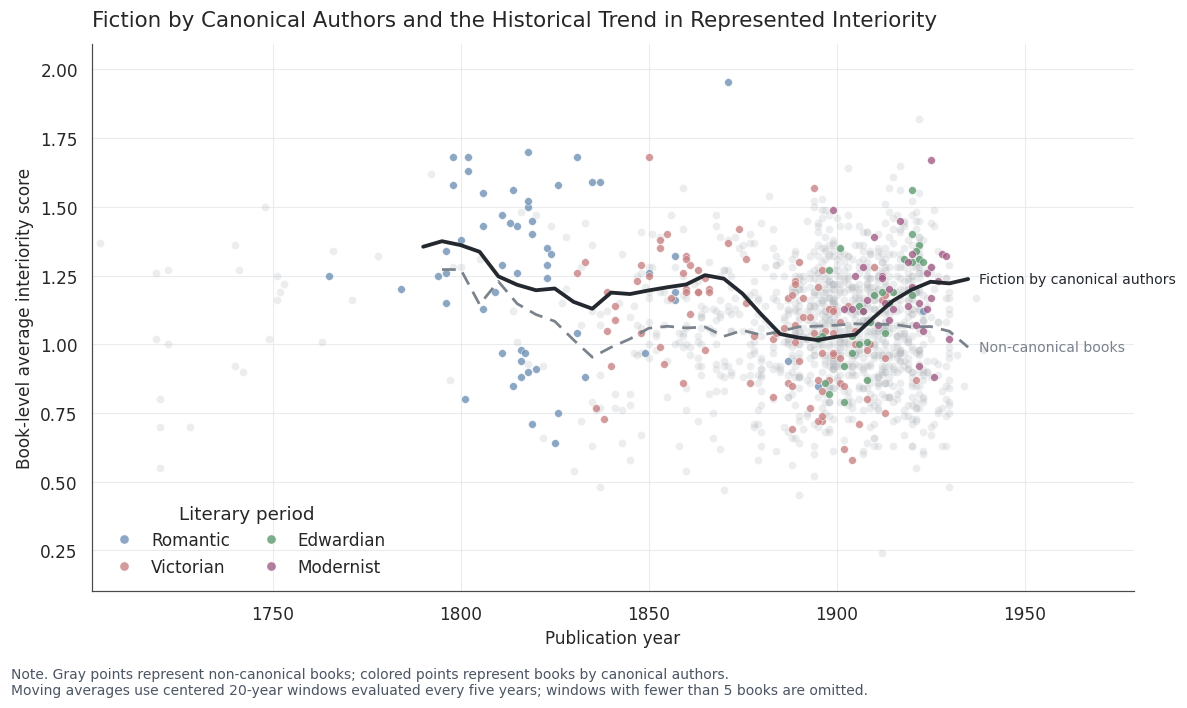

Saved Figure 1:
  /Users/chelseachen/Desktop/interiority/canonical_fiction_exploratory_outputs/figures/figure1_canonical_historical_trend.png
  /Users/chelseachen/Desktop/interiority/canonical_fiction_exploratory_outputs/figures/figure1_canonical_historical_trend.pdf


In [4]:
def centered_moving_average(frame, evaluation_years, label):
    rows = []
    for evaluation_year in evaluation_years:
        in_window = frame["_year"].between(
            evaluation_year - WINDOW_HALF_WIDTH_YEARS,
            evaluation_year + WINDOW_HALF_WIDTH_YEARS,
            inclusive="both",
        )
        values = frame.loc[in_window, "_score"]
        n_books = len(values)
        rows.append(
            {
                "series": label,
                "evaluation_year": int(evaluation_year),
                "window_start": int(evaluation_year - WINDOW_HALF_WIDTH_YEARS),
                "window_end": int(evaluation_year + WINDOW_HALF_WIDTH_YEARS),
                "n_books": int(n_books),
                "estimate": values.mean() if n_books >= MIN_BOOKS_PER_WINDOW else np.nan,
                "omitted": n_books < MIN_BOOKS_PER_WINDOW,
            }
        )
    return pd.DataFrame(rows)


first_evaluation_year = int(np.ceil(full_plot_data["_year"].min() / EVALUATION_STEP_YEARS) * EVALUATION_STEP_YEARS)
last_evaluation_year = int(np.floor(full_plot_data["_year"].max() / EVALUATION_STEP_YEARS) * EVALUATION_STEP_YEARS)
evaluation_years = np.arange(
    first_evaluation_year,
    last_evaluation_year + 1,
    EVALUATION_STEP_YEARS,
)

noncanonical_book_data = data.loc[~data["_is_canonical"]].dropna(
    subset=["_year", "_score"]
).copy()

noncanonical_trend = centered_moving_average(
    noncanonical_book_data,
    evaluation_years,
    "Non-canonical books trend",
)
canonical_trend = centered_moving_average(
    canonical_book_data,
    evaluation_years,
    "Fiction by canonical authors trend",
)
moving_average_data = pd.concat(
    [noncanonical_trend, canonical_trend],
    ignore_index=True,
)

for trend_name, trend_data in moving_average_data.groupby("series", sort=False):
    print(
        f"{trend_name}: {int(trend_data['omitted'].sum())} of {len(trend_data)} windows omitted "
        f"(< {MIN_BOOKS_PER_WINDOW} books)."
    )

moving_average_data.to_csv(TABLE_DIR / "canonical_historical_moving_averages.csv", index=False)

def longest_contiguous_trend_segment(trend):
    """Return the longest uninterrupted run of displayed moving-average estimates."""
    valid = trend.dropna(subset=["estimate"]).sort_values("evaluation_year").copy()
    if valid.empty:
        return valid
    valid["_segment"] = (
        valid["evaluation_year"].diff().ne(EVALUATION_STEP_YEARS).cumsum()
    )
    longest_segment = valid.groupby("_segment").size().idxmax()
    return valid.loc[valid["_segment"].eq(longest_segment)].drop(columns="_segment")


noncanonical_trend_display = longest_contiguous_trend_segment(noncanonical_trend)
canonical_trend_display = longest_contiguous_trend_segment(canonical_trend)

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.scatter(
    noncanonical_book_data["_year"],
    noncanonical_book_data["_score"],
    s=26,
    color="#AAB0B6",
    alpha=0.22,
    linewidths=0,
    rasterized=True,
    zorder=1,
)

observed_periods = [period for period in period_order if period in set(canonical_book_data["_period"])]
for period in observed_periods:
    period_data = canonical_book_data.loc[canonical_book_data["_period"].eq(period)]
    ax.scatter(
        period_data["_year"],
        period_data["_score"],
        s=26,
        color=period_colors[period],
        alpha=0.80,
        edgecolors="white",
        linewidths=0.35,
        zorder=3,
    )

noncanonical_line_color = "#7A828B"
canonical_line_color = "#24292F"
ax.plot(
    noncanonical_trend_display["evaluation_year"],
    noncanonical_trend_display["estimate"],
    color=noncanonical_line_color,
    linewidth=1.8,
    linestyle=(0, (5, 3)),
    zorder=4,
)
ax.plot(
    canonical_trend_display["evaluation_year"],
    canonical_trend_display["estimate"],
    color=canonical_line_color,
    linewidth=2.5,
    zorder=5,
)

for trend, label, color in [
    (noncanonical_trend_display, "Non-canonical books", noncanonical_line_color),
    (canonical_trend_display, "Fiction by canonical authors", canonical_line_color),
]:
    if len(trend):
        endpoint = trend.iloc[-1]
        ax.text(
            endpoint["evaluation_year"] + 3.0,
            endpoint["estimate"],
            label,
            color=color,
            fontsize=9.2,
            fontweight="medium",
            va="center",
            ha="left",
            clip_on=False,
        )

period_legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        markerfacecolor=period_colors[period],
        markeredgecolor="white",
        markeredgewidth=0.35,
        alpha=0.80,
        markersize=6,
        label=period,
    )
    for period in observed_periods
]

ax.set_xlabel("Publication year")
ax.set_ylabel("Book-level average interiority score")
ax.set_title(
    "Fiction by Canonical Authors and the Historical Trend in Represented Interiority",
    loc="left",
    pad=12,
    fontsize=14,
    fontweight="normal",
)
ax.legend(
    handles=period_legend_handles,
    title="Literary period",
    loc="lower left",
    ncol=2,
    columnspacing=1.4,
    handletextpad=0.6,
)
ax.set_xlim(full_plot_data["_year"].min() - 2, full_plot_data["_year"].max() + 40)
ax.grid(axis="both", color="#E4E7EA", linewidth=0.7, alpha=0.8)
ax.margins(y=0.08)
sns.despine(ax=ax)

fig.text(
    0.01,
    0.015,
    "Note. Gray points represent non-canonical books; colored points represent books by canonical authors. \n"
    "Moving averages use centered 20-year windows evaluated every five years; "
    f"windows with fewer than {MIN_BOOKS_PER_WINDOW} books are omitted.",
    ha="left",
    va="bottom",
    fontsize=9.1,
    color="#4B5563",
)
fig.tight_layout(rect=[0, 0.06, 1, 1])
figure1_paths = save_figure(fig, FIGURE_DIR, "figure1_canonical_historical_trend")
plt.show()

print("Saved Figure 1:")
for path in figure1_paths:
    print(f"  {path}")

## Figure 2. Author means with book-level period summaries

Books are first aggregated to one row per author and canonical period. Bootstrap intervals resample those author rows within each period, so every author contributes equal weight to the period mean.

In [5]:
author_period_data = (
    canonical_author_book_data.groupby(["_period", "_author"], observed=True, as_index=False)
    .agg(
        mean_interiority=("_score", "mean"),
        n_books=("_score", "size"),
        minimum_publication_year=("_year", "min"),
        maximum_publication_year=("_year", "max"),
    )
    .rename(columns={"_period": "canonical_period", "_author": "author"})
)

author_period_counts = author_period_data.groupby("author")["canonical_period"].nunique()
authors_in_multiple_periods = author_period_counts[author_period_counts.gt(1)]
if len(authors_in_multiple_periods):
    print(
        f"Diagnostic: {len(authors_in_multiple_periods)} authors occur in more than one period; "
        "the requested author-period aggregation yields one point per author in each assigned period."
    )
else:
    print("Diagnostic: every author occurs in exactly one canonical period.")


def bootstrap_author_mean(values, period):
    scores = np.asarray(values, dtype=float)
    n_authors = len(scores)
    if n_authors < MIN_AUTHORS_FOR_CI:
        return np.nan, np.nan, f"Suppressed (n < {MIN_AUTHORS_FOR_CI})"
    period_offset = sum(ord(character) for character in str(period))
    rng = np.random.default_rng(RANDOM_SEED + period_offset)
    draws = np.empty(BOOTSTRAP_REPETITIONS, dtype=float)
    chunk_size = 1_000
    for start in range(0, BOOTSTRAP_REPETITIONS, chunk_size):
        stop = min(start + chunk_size, BOOTSTRAP_REPETITIONS)
        indices = rng.integers(0, n_authors, size=(stop - start, n_authors))
        draws[start:stop] = scores[indices].mean(axis=1)
    lower, upper = np.quantile(draws, [0.025, 0.975])
    return float(lower), float(upper), "Displayed"


summary_rows = []
observed_author_periods = [period for period in period_order if period in set(author_period_data["canonical_period"])]
for period in observed_author_periods:
    group = author_period_data.loc[author_period_data["canonical_period"].eq(period)]
    lower, upper, ci_status = bootstrap_author_mean(group["mean_interiority"], period)
    summary_rows.append(
        {
            "canonical_period": period,
            "n_authors": len(group),
            "n_books": int(group["n_books"].sum()),
            "mean_author_interiority": group["mean_interiority"].mean(),
            "median_author_interiority": group["mean_interiority"].median(),
            "sd_author_interiority": group["mean_interiority"].std(ddof=1),
            "bootstrap_ci_lower": lower,
            "bootstrap_ci_upper": upper,
            "bootstrap_ci_status": ci_status,
        }
    )

author_period_summary = pd.DataFrame(summary_rows)
author_period_data.to_csv(TABLE_DIR / "canonical_author_period_data.csv", index=False)
author_period_summary.to_csv(TABLE_DIR / "canonical_author_period_summary.csv", index=False)

display(Markdown("**Author-period aggregation (diagnostic columns included)**"))
display(author_period_data)

Diagnostic: every author occurs in exactly one canonical period.


**Author-period aggregation (diagnostic columns included)**

,canonical_period,author,mean_interiority,n_books,minimum_publication_year,maximum_publication_year
0,Edwardian,Arnold Bennett,1.155000,10,1901,1923
1,Edwardian,H. G. Wells,1.013000,10,1895,1922
2,Edwardian,John Galsworthy,1.241000,10,1898,1921
3,Modernist,Aldous Huxley,1.133333,3,1921,1925
4,Modernist,D. H. Lawrence,1.151111,9,1911,1930
5,Modernist,E. M. Forster,1.236000,5,1905,1924
6,Modernist,Elizabeth Bowen,1.275000,2,1927,1929
7,Modernist,James Joyce,1.120000,2,1914,1922
8,Modernist,Joseph Conrad,1.248889,9,1899,1925
9,Modernist,Virginia Woolf,1.255000,4,1915,1925


In [6]:
display(Markdown("**Author-level period summary**"))
display(
    author_period_summary.style.format(
        {
            "mean_author_interiority": "{:.3f}",
            "median_author_interiority": "{:.3f}",
            "sd_author_interiority": "{:.3f}",
            "bootstrap_ci_lower": "{:.3f}",
            "bootstrap_ci_upper": "{:.3f}",
        },
        na_rep="—",
    )
)

**Author-level period summary**

,canonical_period,n_authors,n_books,mean_author_interiority,median_author_interiority,sd_author_interiority,bootstrap_ci_lower,bootstrap_ci_upper,bootstrap_ci_status
0,Romantic,12,57,1.272,1.295,0.198,1.161,1.375,Displayed
1,Victorian,14,97,1.113,1.135,0.183,1.021,1.205,Displayed
2,Edwardian,3,30,1.136,1.155,0.115,—,—,Suppressed (n < 5)
3,Modernist,7,34,1.203,1.236,0.065,1.158,1.245,Displayed


In [7]:
def bootstrap_book_mean(values, period):
    scores = np.asarray(values, dtype=float)
    n_books = len(scores)
    if n_books == 0:
        return np.nan, np.nan
    period_offset = sum(ord(character) for character in str(period))
    rng = np.random.default_rng(RANDOM_SEED + 10_000 + period_offset)
    draws = np.empty(BOOTSTRAP_REPETITIONS, dtype=float)
    chunk_size = 1_000
    for start in range(0, BOOTSTRAP_REPETITIONS, chunk_size):
        stop = min(start + chunk_size, BOOTSTRAP_REPETITIONS)
        indices = rng.integers(0, n_books, size=(stop - start, n_books))
        draws[start:stop] = scores[indices].mean(axis=1)
    lower, upper = np.quantile(draws, [0.025, 0.975])
    return float(lower), float(upper)


book_period_rows = []
observed_book_periods = [
    period
    for period in period_order
    if period in set(canonical_book_data["_period"])
]
for period in observed_book_periods:
    period_books = canonical_book_data.loc[
        canonical_book_data["_period"].eq(period),
        "_score",
    ]
    lower, upper = bootstrap_book_mean(period_books, period)
    book_period_rows.append(
        {
            "canonical_period": period,
            "n_books": len(period_books),
            "mean_book_interiority": period_books.mean(),
            "bootstrap_ci_lower": lower,
            "bootstrap_ci_upper": upper,
        }
    )

book_period_summary = pd.DataFrame(book_period_rows)
book_period_summary.to_csv(
    TABLE_DIR / "canonical_book_period_summary.csv",
    index=False,
)

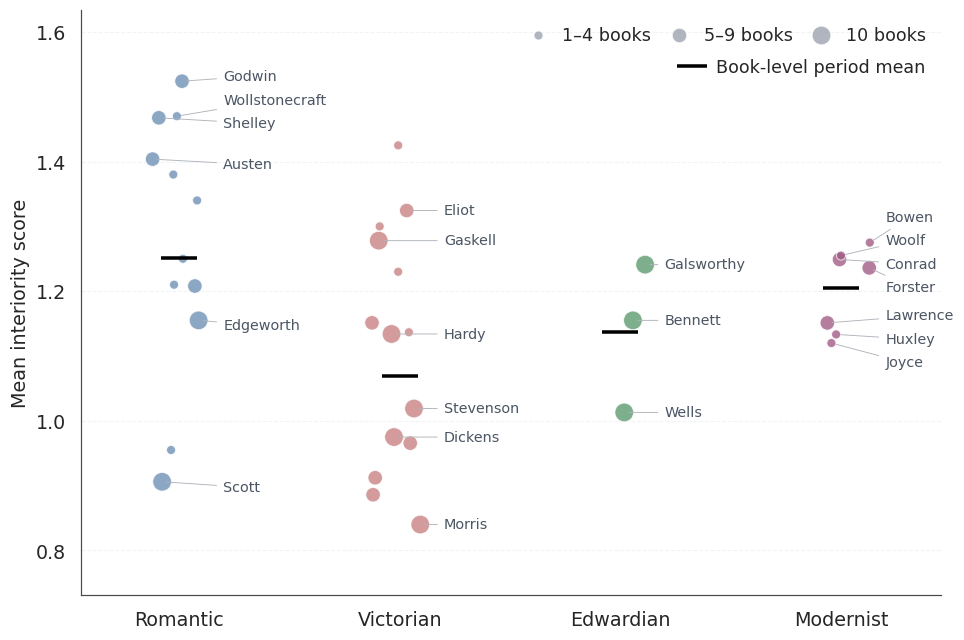

Saved Figure 2:
  /Users/chelseachen/Desktop/interiority/canonical_fiction_exploratory_outputs/figures/figure2_author_level_canonical_periods.png
  /Users/chelseachen/Desktop/interiority/canonical_fiction_exploratory_outputs/figures/figure2_author_level_canonical_periods.pdf


In [8]:
def author_point_area(book_counts):
    """Use the same book-count categories for plotted areas and the size legend."""
    counts = np.asarray(book_counts, dtype=float)
    return np.select([counts < 5, counts < 10], [35.0, 90.0], default=150.0)


def spaced_label_positions(values, minimum_gap=0.033):
    """Return vertically separated label positions while preserving rank."""
    values = np.asarray(values, dtype=float)
    order = np.argsort(values)
    sorted_values = values[order]
    adjusted = sorted_values.copy()
    for index in range(1, len(adjusted)):
        adjusted[index] = max(adjusted[index], adjusted[index - 1] + minimum_gap)
    adjusted -= adjusted.mean() - sorted_values.mean()
    result = np.empty_like(adjusted)
    result[order] = adjusted
    return result


with plt.rc_context({
    "font.size": 12.5,
    "axes.labelsize": 12.5,
    "axes.titlesize": 12.5,
    "xtick.labelsize": 12.5,
    "ytick.labelsize": 12.5,
    "legend.fontsize": 12.5,
    "legend.title_fontsize": 12.5,
    "figure.titlesize": 12.5,
}):
    fig, ax = plt.subplots(figsize=(9, 6))
    jitter_rng = np.random.default_rng(RANDOM_SEED)
    x_positions = {period: index for index, period in enumerate(observed_author_periods)}

    for period in observed_author_periods:
        group = author_period_data.loc[author_period_data["canonical_period"].eq(period)]
        x_center = x_positions[period]
        jitter = jitter_rng.uniform(-0.14, 0.14, size=len(group))
        x_values = x_center + jitter
        ax.scatter(
            x_values,
            group["mean_interiority"],
            s=author_point_area(group["n_books"]),
            color=period_colors[period],
            alpha=0.80,
            edgecolors="white",
            linewidths=0.6,
            zorder=3,
        )

        period_key = period.casefold()
        if period_key in {"edwardian", "modernist"}:
            label_mask = np.ones(len(group), dtype=bool)
        elif period_key in {"romantic", "victorian"}:
            requested_surnames = (
                group["author"].astype(str).str.split().str[-1].isin(
                    {"Austen", "Eliot", "Godwin", "Shelley", "Wollstonecraft"}
                )
            )
            label_mask = (
                group["n_books"].eq(10) | requested_surnames
            ).to_numpy()
        else:
            label_mask = np.zeros(len(group), dtype=bool)

        if label_mask.any():
            label_group = group.loc[label_mask]
            label_point_x = x_values[label_mask]
            label_y_values = spaced_label_positions(
                label_group["mean_interiority"],
                minimum_gap=0.036,
            )
            label_x = x_center + 0.20
            for point_x, label_y, row in zip(
                label_point_x,
                label_y_values,
                label_group.itertuples(index=False),
            ):
                surname = str(row.author).split()[-1]
                ax.annotate(
                    surname,
                    xy=(point_x, row.mean_interiority),
                    xytext=(label_x, label_y),
                    textcoords="data",
                    fontsize=9.4,
                    color="#4B5563",
                    ha="left",
                    va="center",
                    arrowprops={
                        "arrowstyle": "-",
                        "color": "#B0B5BB",
                        "linewidth": 0.6,
                        "shrinkA": 2,
                        "shrinkB": 3,
                    },
                    zorder=5,
                )

    summary_color = "#000000"
    for row in book_period_summary.itertuples(index=False):
        ax.plot(
            x_positions[row.canonical_period],
            row.mean_book_interiority,
            marker="_",
            markersize=24,
            markeredgecolor=summary_color,
            markerfacecolor="white",
            markeredgewidth=2.3,
            linestyle="none",
            zorder=6,
        )

    ax.set_xticks(range(len(observed_author_periods)), observed_author_periods)
    ax.set_xlabel("")
    ax.set_ylabel("Mean interiority score")
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", color="#EEF0F2", linewidth=0.7, linestyle="--", alpha=0.8)
    ax.margins(x=0.10, y=0.16)
    sns.despine(ax=ax)

    size_handles = [
        ax.scatter(
            [],
            [],
            s=author_point_area([count])[0],
            color="#9CA3AF",
            alpha=0.80,
            edgecolors="white",
            linewidths=0.6,
            label=label,
        )
        for count, label in [
            (1, "1–4 books"),
            (5, "5–9 books"),
            (10, "10 books" if author_period_data["n_books"].max() <= 10 else "10+ books"),
        ]
    ]
    size_legend = ax.legend(
        handles=size_handles,
        loc="upper right", bbox_to_anchor=(1, 1), alignment="right",
        fontsize=11.5,
        ncol=3,
        columnspacing=0.6,
        handlelength=2.0, handletextpad=0.4, labelspacing=0.35,
    )
    for text in size_legend.get_texts():
        text.set_fontsize(11.5)
    ax.add_artist(size_legend)
    mean_handle = Line2D(
        [], [], marker="_", markersize=20, markeredgewidth=2.3,
        color=summary_color, linestyle="none", label="Book-level period mean",
    )
    ax.legend(
        handles=[mean_handle], loc="upper right", alignment="right",
        bbox_to_anchor=(1, 0.945), handlelength=2.0, handletextpad=0.4,
        fontsize=11.5,
    )


    fig.tight_layout()
    figure2_paths = save_figure(fig, FIGURE_DIR, "figure2_author_level_canonical_periods")
    plt.show()

print("Saved Figure 2:")
for path in figure2_paths:
    print(f"  {path}")

In [9]:
# Show both period means numerically, separately from the figure.
period_mean_comparison = pd.DataFrame({
    "Book-level mean": canonical_book_data.groupby("_period")["_score"].mean(),
    "Author-level mean": author_period_data.groupby("canonical_period")["mean_interiority"].mean(),
}).reindex(observed_author_periods)
period_mean_comparison.index.name = "Literary period"
display(period_mean_comparison.style.format("{:.6f}"))
period_mean_comparison.to_csv(TABLE_DIR / "canonical_period_mean_comparison.csv")

,Book-level mean,Author-level mean
Literary period,,
Romantic,1.251825,1.272440
Victorian,1.069175,1.112653
Edwardian,1.136333,1.136333
Modernist,1.205588,1.202762


## Figure 3. Book-level interiority by canonical period

This dot-whisker plot returns to the book as the unit of analysis. Period means weight books equally, and 95% confidence intervals bootstrap books within each canonical period.

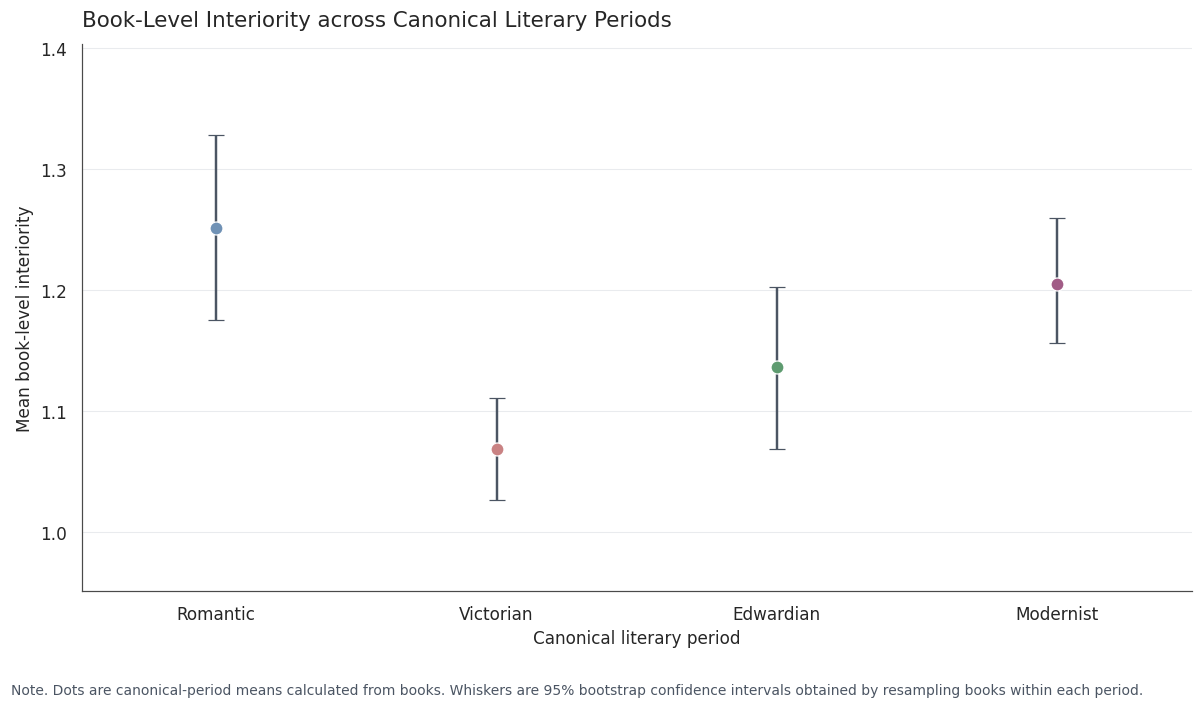

Saved Figure 3:
  /Users/chelseachen/Desktop/interiority/canonical_fiction_exploratory_outputs/figures/figure3_book_level_canonical_periods.png
  /Users/chelseachen/Desktop/interiority/canonical_fiction_exploratory_outputs/figures/figure3_book_level_canonical_periods.pdf


In [10]:
fig, ax = plt.subplots(figsize=(11, 6.5))
for x_value, row in enumerate(book_period_summary.itertuples(index=False)):
    ax.errorbar(
        x_value,
        row.mean_book_interiority,
        yerr=[
            [row.mean_book_interiority - row.bootstrap_ci_lower],
            [row.bootstrap_ci_upper - row.mean_book_interiority],
        ],
        fmt="o",
        markersize=8.5,
        color=period_colors[row.canonical_period],
        ecolor="#4B5563",
        markeredgecolor="white",
        markeredgewidth=0.8,
        elinewidth=1.6,
        capsize=5,
        zorder=4,
    )

ax.set_xticks(
    range(len(book_period_summary)),
    book_period_summary["canonical_period"],
)
ax.set_xlabel("Canonical literary period")
ax.set_ylabel("Mean book-level interiority")
ax.set_title(
    "Book-Level Interiority across Canonical Literary Periods",
    loc="left",
    pad=12,
    fontsize=14,
    fontweight="normal",
)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", color="#E4E7EA", linewidth=0.7, alpha=0.8)
ax.margins(x=0.16, y=0.25)
sns.despine(ax=ax)

fig.text(
    0.01,
    0.015,
    "Note. Dots are canonical-period means calculated from books. Whiskers are 95% bootstrap confidence "
    "intervals obtained by resampling books within each period.",
    ha="left",
    va="bottom",
    fontsize=9.1,
    color="#4B5563",
)
fig.tight_layout(rect=[0, 0.06, 1, 1])
figure3_paths = save_figure(fig, FIGURE_DIR, "figure3_book_level_canonical_periods")
plt.show()

print("Saved Figure 3:")
for path in figure3_paths:
    print(f"  {path}")

## Figure 4. Fiction by canonical authors with bootstrap confidence intervals

This copy of Figure 1 includes only books by canonical authors. The moving average uses the same estimates, windows, sample-count threshold, and continuous display segment as Figure 1. The shaded band gives pointwise 95% percentile bootstrap confidence intervals, resampling books within each window.

Figure 4: 17 of 47 windows omitted (< 5 books); 10,000 book-bootstrap resamples per eligible window.


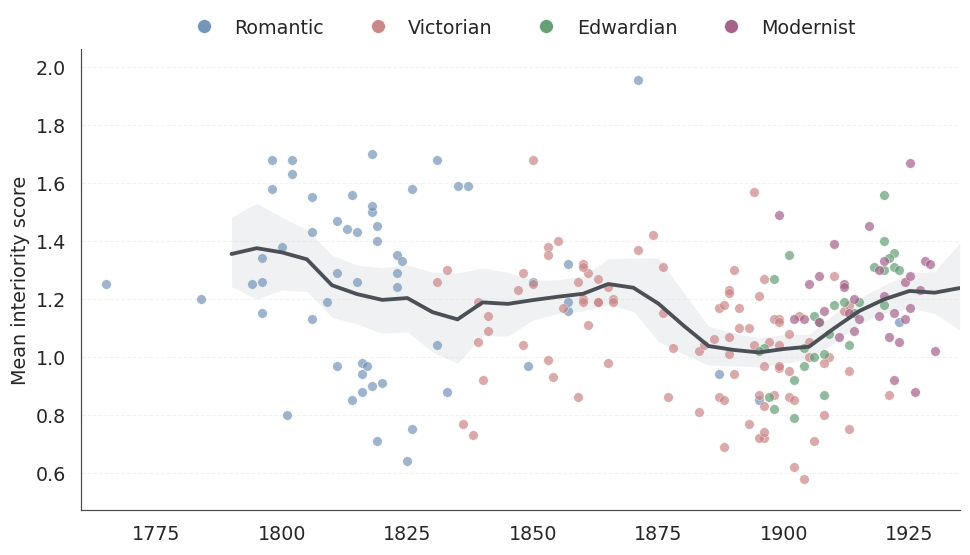

Saved Figure 4:
  /Users/chelseachen/Desktop/interiority/canonical_fiction_exploratory_outputs/figures/figure4_canonical_historical_trend_bootstrap.png
  /Users/chelseachen/Desktop/interiority/canonical_fiction_exploratory_outputs/figures/figure4_canonical_historical_trend_bootstrap.pdf


In [11]:
# Bootstrap books independently within each inclusive centered window.
# Keep Figure 1's moving-average estimates, evaluation grid, and minimum count.
figure4_trend = canonical_trend.copy()
figure4_trend['ci_lower'] = np.nan
figure4_trend['ci_upper'] = np.nan

for row_index, row in figure4_trend.iterrows():
    if row['omitted']:
        continue
    values = canonical_book_data.loc[
        canonical_book_data['_year'].between(
            row['window_start'], row['window_end'], inclusive='both'
        ),
        '_score',
    ].to_numpy(float)
    rng = np.random.default_rng(
        np.random.SeedSequence([RANDOM_SEED, 4, int(row['evaluation_year'])])
    )
    draws = np.empty(BOOTSTRAP_REPETITIONS, dtype=float)
    for start in range(0, BOOTSTRAP_REPETITIONS, 1_000):
        stop = min(start + 1_000, BOOTSTRAP_REPETITIONS)
        indices = rng.integers(0, len(values), size=(stop - start, len(values)))
        draws[start:stop] = values[indices].mean(axis=1)
    figure4_trend.loc[row_index, ['ci_lower', 'ci_upper']] = np.quantile(
        draws, [0.025, 0.975]
    )

figure4_trend_display = figure4_trend.loc[
    figure4_trend['evaluation_year'].isin(canonical_trend_display['evaluation_year'])
].copy()
figure4_trend.to_csv(
    TABLE_DIR / 'figure4_canonical_historical_bootstrap.csv', index=False
)
print(
    f"Figure 4: {int(figure4_trend['omitted'].sum())} of {len(figure4_trend)} "
    f"windows omitted (< {MIN_BOOKS_PER_WINDOW} books); "
    f"{BOOTSTRAP_REPETITIONS:,} book-bootstrap resamples per eligible window."
)

# Apply Figure 4 typography locally so other figures retain their styling.
with plt.rc_context({
    "font.size": 12.5,
    "axes.labelsize": 12.5,
    "axes.titlesize": 12.5,
    "xtick.labelsize": 12.5,
    "ytick.labelsize": 12.5,
    "legend.fontsize": 12.5,
    "legend.title_fontsize": 12.5,
    "figure.titlesize": 12.5,
}):
    fig, ax = plt.subplots(figsize=(9, 5.5))
    observed_periods = [period for period in period_order if period in set(canonical_book_data["_period"])]
    for period in observed_periods:
        period_data = canonical_book_data.loc[canonical_book_data["_period"].eq(period)]
        ax.scatter(
            period_data["_year"],
            period_data["_score"],
            s=39,
            color=period_colors[period],
            alpha=0.68,
            edgecolors="white",
            linewidths=0.35,
            zorder=3,
        )

    # Reuse exactly the same moving-average estimates and displayed years as Figure 1.
    ax.fill_between(
        figure4_trend_display['evaluation_year'].to_numpy(float),
        figure4_trend_display['ci_lower'].to_numpy(float),
        figure4_trend_display['ci_upper'].to_numpy(float),
        color='#D1D5DB',
        alpha=0.32,
        linewidth=0,
        zorder=2,
    )
    ax.plot(
        figure4_trend_display['evaluation_year'],
        figure4_trend_display['estimate'],
        color='#4B5056',
        linewidth=2.5,
        zorder=5,
    )

    period_legend_handles = [
        Line2D(
            [0],
            [0],
            marker="o",
            linestyle="none",
            markerfacecolor=period_colors[period],
            markeredgecolor="white",
            markeredgewidth=0.35,
            alpha=0.95,
            markersize=9,
            label=period,
        )
        for period in observed_periods
    ]

    ax.set_xlabel("")
    ax.set_ylabel("Mean interiority score")
    ax.legend(
        handles=period_legend_handles,
        loc="lower center",
        bbox_to_anchor=(0.5, 1.008),
        ncol=len(observed_periods),
        columnspacing=1.8,
        handletextpad=0.6,
        borderaxespad=0,
    )
    ax.set_xlim(1760, 1935)
    ax.set_xticks(np.arange(1775, 1936, 25))
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", color="#EEF0F2", linewidth=0.7, linestyle="--", alpha=0.8)
    ax.margins(y=0.08)
    sns.despine(ax=ax)

    fig.tight_layout(rect=[0, 0, 1, 0.95])
    figure4_paths = save_figure(fig, FIGURE_DIR, "figure4_canonical_historical_trend_bootstrap")
    plt.show()

print("Saved Figure 4:")
for path in figure4_paths:
    print(f"  {path}")

## Interpretation and scope

Figure 1 is descriptive: it places canonical fiction against the full corpus over publication time and compares centered moving averages without estimating a causal or inferential model.

Figure 2 shows one point per author, while its gray summaries use books as the unit of analysis. The author points prevent prolific authors from visually appearing multiple times, whereas the gray period means and confidence intervals weight every represented book equally.

Figure 3 treats the book as the unit of analysis and therefore gives greater aggregate weight to authors represented by more books. Its bootstrap intervals resample books within each period.

The Edwardian category contains a small number of theoretically selected authors. Comparisons involving this period should therefore be interpreted as exploratory; its author-level period mean is shown in Figure 2, but its author-bootstrap interval is suppressed under the prespecified minimum-author rule.